In [1]:
import pandas as pd
import ast
import sys
import os
import numpy as np
from semopy import Model, calc_stats
from functions.diagnose_utils import add_dx_features


In [2]:
from server_config import DATA_PATH
sys.path.append(os.path.abspath("functions"))
from functions.therapist_effect import bootstrap_icc_cluster, fit_icc_point

### 1. Therapist data

In [3]:
df_th = pd.read_csv(DATA_PATH + "/df_th_nopr_experience_corrected_200624_LB.csv", sep=";",low_memory = "False")

In [4]:
keep_cols_th = ['therapist_id', 't0_method_t_CBT','t0_method_t_PDT','t0_method_t_ST','t0_method_t_AP', 't0_appliedmethod_t_VT', 't0_appliedmethod_t_TP',
             't0_appliedmethod_t_AP', 't0_appliedmethod_t_ST','t0_appliedmethod_t_Other','t0_location_t','t0_gender_t',
 't0_relationship_t','t0_sexualorientation_t','t0_children_t','t0_age_t', 't0_experience_t','t0_license_t', 't0_bfi_t_1',
 't0_bfi_t_2','t0_bfi_t_3','t0_bfi_t_4','t0_bfi_t_5','t0_bfi_t_6','t0_bfi_t_7','t0_bfi_t_8','t0_bfi_t_9','t0_bfi_t_10','t0_practice_t']

In [5]:
labels = ["VT", "TP", "AP", "ST", "Other"]  

col = df_th["t0_appliedmethod_t_A"]

# 1) Parse strings like "[True, False, ...]" -> list
col = col.map(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)

# 2) Unwrap nested lists like [[True, False, ...]] -> [True, False, ...]
col = col.map(lambda x: x[0] if isinstance(x, (list, tuple)) and len(x) == 1 and isinstance(x[0], (list, tuple)) else x)

# 3) Safety: replace missing/invalid with all-False (or raise if you prefer)
def ensure_five(x):
    if isinstance(x, (list, tuple)) and len(x) == 5:
        return list(x)
    if pd.isna(x):
        return [False]*5

col = col.map(ensure_five)

# 4) Build the indicator columns
method_df = (
    pd.DataFrame(col.tolist(), index=df_th.index, columns=labels)
      .astype(int)
      .add_prefix("t0_appliedmethod_t_")
)

In [6]:
df_th = df_th.join(method_df)


In [7]:
df_th = df_th[keep_cols_th]

In [8]:
# BFI-10 items (1–5), reverse-code, then build subscale SUMS using df_th and t0-prefix
bfi_items = [f"t0_bfi_t_{i}" for i in range(1, 11)]
df_th[bfi_items] = df_th[bfi_items].apply(pd.to_numeric, errors="coerce")


# Subscale sums (2 items each)
df_th["t0_bfi_t_extraversion"]     = df_th[["t0_bfi_t_1", "t0_bfi_t_6"]].sum(axis=1)
df_th["t0_bfi_t_agreeableness"]    = df_th[["t0_bfi_t_2",   "t0_bfi_t_7"]].sum(axis=1)
df_th["t0_bfi_t_conscientiousness"]= df_th[["t0_bfi_t_3", "t0_bfi_t_8"]].sum(axis=1)
df_th["t0_bfi_t_neuroticism"]      = df_th[["t0_bfi_t_4", "t0_bfi_t_9"]].sum(axis=1)
df_th["t0_bfi_t_openness"]         = df_th[["t0_bfi_t_5", "t0_bfi_t_10"]].sum(axis=1)




### 2. Patient data

In [9]:
df_pat = pd.read_json(DATA_PATH + "/TONI_pat_corrected_20241025_raw.json")

In [10]:
df_pat_diagnose = pd.read_csv(DATA_PATH + "/patient_data_diagnosed.csv", encoding="latin1", low_memory=False)
df_pat_diagnose_short = df_pat_diagnose[["patient_id","primarydiagnosis_tp","comorbiddiagnosis_tp"]]

In [11]:

df_feat, uni_p, uni_c = add_dx_features(
    df_pat_diagnose,
    primary_col="primarydiagnosis_tp",
    comorbid_col="comorbiddiagnosis_tp",
    level_multihot=3,
    allowed_letters=("F",),
    primary_prefix="pdx3",
    comorbid_prefix="cdx3",
    f43_fallback="other",
    keep_lists=True,
    missing_label="Missing",
    multihot_dtype=np.int8,   # numeric 0/1
)

# # sanity checks
print(df_feat[["primary_dx_icd10_3","primary_dx_table2"]].head())
mh_cols = [c for c in df_feat.columns if c.startswith(("pdx3_", "cdx3_"))]

  primary_dx_icd10_3    primary_dx_table2
0                F32  Affective disorders
1                F32  Affective disorders
2                F32  Affective disorders
3                F32  Affective disorders
4                F32  Affective disorders


In [12]:
df_feat = df_feat.drop_duplicates(subset="patient_id")

In [13]:
df_feat = df_feat[["patient_id", "primary_count", "primary_list"]]

In [14]:
keep_cols = (
    # IDs / study
    ['patient_id', 'therapist_id', 'u_registrationDate_p'] +

    # Demographics / baseline
    ['t0_age_p','t0_gender_p','t0_school_p','t0_employment_p','t0_location_p'] +
    [f"t0_therapy_p_{i}" for i in range(1, 4)] +
    ['t0_familyhistory_p','t0_meds_p','t0_relationship_p','t0_ses_p'] +
    [f"t0_migration_p_{i}" for i in range(1, 4)] +
    [f"surveys.t0.answers.1585.discrimination_{i}" for i in range(1, 6)] +
    [f"t0_disease_p_{c}" for c in list('ABCDEFG')] +

    # t0 scales
    [f"t0_phq_p_{i}" for i in range(1, 9)] +
    [f"t0_gad_p_{i}" for i in range(1, 7+1)] +
    [f"t0_swls_p_{i}" for i in range(1, 5+1)] +
    [f"t0_aqol_p_{i}" for i in range(1, 35+1)] +
    [f"t0_ede_p_{i}" for i in range(1, 8+1)] +
    (['t0_audit_p_filter'] + [f"t0_audit_p_{i}" for i in range(1, 3+1)]) +
    (['t0_dudit_p_filter'] + [f"t0_dudit_p_{i}" for i in range(1, 4+1)]) +
    [f"t0_msfq_p_{i}" for i in range(1, 5+1)] +
    [f"t0_pid_p_{i}" for i in range(1, 36+1)] +
    [f"t0_opd_p_{i}" for i in range(1, 12+1)] +
    [f"t0_ace_p_{i}" for i in range(1, 10+1)] +
    [f"t0_ask_p_{i}" for i in range(1, 3+1)] +
    [f"t0_mhse_p_{i}" for i in range(1, 6+1)] +

    # t1 scales
    [f"t1_phq_p_{i}" for i in range(1, 8+1)] +
    [f"t1_gad_p_{i}" for i in range(1, 7+1)] +
    [f"t1_multi_p_{i}" for i in range(1, 7+1)] +
    [f"t1_cpps_p_{i}" for i in range(1, 20+1)] +

    # t2 scales
    [f"t2_phq_p_{i}" for i in range(1, 8+1)] +
    [f"t2_gad_p_{i}" for i in range(1, 7+1)] +

    
    # t3 scales
    [f"t3_phq_p_{i}" for i in range(1, 8+1)] +
    [f"t3_gad_p_{i}" for i in range(1, 7+1)] +


    # alliance / matching

    [ 't0_change_p_1', 't0_change_p_2', 't0_dropout_p'] +
    ['t0_primarydiagnosis_tp', 't0_comorbiddiagnosis_tp']

)


In [15]:
df_pat= df_pat[keep_cols]

#### 2.1 Calculate Subscales for self-report data

#### Outcome (PHQ + GAD)

In [16]:
# define item columns
phq_cols_t1 = [f"t1_phq_p_{i}" for i in range(1, 9)]
gad_cols_t1 = [f"t1_gad_p_{i}" for i in range(1, 8)]

mask_complete = df_pat[phq_cols_t1 + gad_cols_t1].notna().all(axis=1)
df_pat_clean = df_pat.loc[mask_complete].copy()

In [17]:
df_pat_clean["t1_phq8_total"] = df_pat_clean[phq_cols_t1].sum(axis=1)
df_pat_clean["t1_gad7_total"] = df_pat_clean[gad_cols_t1].sum(axis=1)

In [18]:
df_pat_clean["t1_distress_sum"] = (
    df_pat_clean["t1_phq8_total"] + df_pat_clean["t1_gad7_total"]
)

In [19]:
# define item columns
phq_cols_t0 = [f"t0_phq_p_{i}" for i in range(1, 9)]
gad_cols_t0 = [f"t0_gad_p_{i}" for i in range(1, 8)]

In [20]:
df_pat_clean["t0_phq8_p_sum"] = df_pat_clean[phq_cols_t0].sum(axis=1)
df_pat_clean["t0_gad7_p_sum"] = df_pat_clean[gad_cols_t0].sum(axis=1)

In [21]:
df_pat_clean["t0_distress_sum"] = (
    df_pat_clean["t0_phq8_p_sum"] + df_pat_clean["t0_gad7_p_sum"]
)

#### SWLS Baseline

In [22]:
swls_cols_t0 = [f"t0_swls_p_{i}" for i in range(1, 6)]

In [23]:
df_pat_clean["t0_swls_p_sum"] = df_pat_clean[swls_cols_t0].sum(axis=1)

#### Aqol Baseline

In [24]:
aqol_map = {
    "t0_aqol_p_coping": ['t0_aqol_p_1', 't0_aqol_p_21', 't0_aqol_p_29'],
    "t0_aqol_p_relationship": ['t0_aqol_p_2', 't0_aqol_p_4', 't0_aqol_p_9', 't0_aqol_p_10',
                               't0_aqol_p_23', 't0_aqol_p_31', 't0_aqol_p_34'],
    "t0_aqol_p_independent_living": ['t0_aqol_p_3', 't0_aqol_p_15', 't0_aqol_p_19', 't0_aqol_p_30'],
    "t0_aqol_p_mental_health": ['t0_aqol_p_5', 't0_aqol_p_8', 't0_aqol_p_12', 't0_aqol_p_14',
                                't0_aqol_p_16', 't0_aqol_p_18', 't0_aqol_p_33', 't0_aqol_p_35'],
    "t0_aqol_p_pain": ['t0_aqol_p_6', 't0_aqol_p_22', 't0_aqol_p_24'],
    "t0_aqol_p_self_worth": ['t0_aqol_p_7', 't0_aqol_p_13', 't0_aqol_p_26'],
    "t0_aqol_p_happiness": ['t0_aqol_p_17', 't0_aqol_p_20', 't0_aqol_p_25', 't0_aqol_p_27'],
    "t0_aqol_p_senses": ['t0_aqol_p_11', 't0_aqol_p_28', 't0_aqol_p_32'],
}

In [25]:
df_pat_clean = df_pat_clean.assign(**{scale: df_pat_clean[items].mean(axis=1) for scale, items in aqol_map.items()})


#### EDE Baseline

In [26]:
df_pat_clean["t0_ede_p_sum"] = df_pat_clean[[f"t0_ede_p_{i}" for i in range(1, 9)]].sum(axis=1)


#### Audit Baseline

In [27]:
aud_items = [f"t0_audit_p_{i}" for i in range(1, 5)]
fcol = "t0_audit_p_filter"

# set all AUDIT item columns to 0 if filter == 0
df_pat_clean.loc[df_pat_clean[fcol].eq(0), aud_items] = 0

# sum AUDIT items only if filter == 1; otherwise set total to 0
df_pat_clean["t0_audit_p_sum"] = np.where(
    df_pat_clean[fcol].eq(1),
    df_pat_clean[aud_items].sum(axis=1),
    0
)

#### Dudit Baseline

In [28]:
dud_items = [f"t0_dudit_p_{i}" for i in range(1, 5)]
fcol = "t0_dudit_p_filter"

# set all AUDIT item columns to 0 if filter == 0
df_pat_clean.loc[df_pat_clean[fcol].eq(0), dud_items] = 0

# sum AUDIT items only if filter == 1; otherwise set total to 0
df_pat_clean["t0_dudit_p_sum"] = np.where(
    df_pat_clean[fcol].eq(1),
    df_pat_clean[dud_items].sum(axis=1),
    0
)

#### MFSQ Baseline

In [29]:
msfq_cols = [f"t0_msfq_p_{i}" for i in range(1, 6)]
df_pat_clean[msfq_cols] = df_pat_clean[msfq_cols].apply(pd.to_numeric, errors="coerce")

df_pat_clean["t0_msfq_p_sum"] = df_pat_clean[msfq_cols].sum(axis=1)

#### PID5BF+ Baseline

In [30]:
import pandas as pd

# -----------------------------
# PID-5 BF+ facets (2 items each) and domains (6 items each)
# -----------------------------
facet_map = {
    # Negative Affectivity facets
    "t0_pid_f_emo_lability":     ["t0_pid_p_1",  "t0_pid_p_19"],
    "t0_pid_f_anxiousness":      ["t0_pid_p_7",  "t0_pid_p_25"],
    "t0_pid_f_sep_insecurity":   ["t0_pid_p_13", "t0_pid_p_31"],  # note: 31 (not 30)

    # Detachment facets
    "t0_pid_f_withdrawal":       ["t0_pid_p_4",  "t0_pid_p_22"],
    "t0_pid_f_anhedonia":        ["t0_pid_p_10", "t0_pid_p_28"],
    "t0_pid_f_intimacy_avoid":   ["t0_pid_p_16", "t0_pid_p_34"],

    # Antagonism facets
    "t0_pid_f_manipulativeness": ["t0_pid_p_2",  "t0_pid_p_20"],
    "t0_pid_f_deceitfulness":    ["t0_pid_p_8",  "t0_pid_p_26"],
    "t0_pid_f_grandiosity":      ["t0_pid_p_14", "t0_pid_p_32"],

    # Disinhibition facets
    "t0_pid_f_irresponsibility": ["t0_pid_p_3",  "t0_pid_p_21"],
    "t0_pid_f_impulsivity":      ["t0_pid_p_9",  "t0_pid_p_27"],
    "t0_pid_f_distractibility":  ["t0_pid_p_15", "t0_pid_p_33"],

    # Psychoticism facets
    "t0_pid_f_unusual_beliefs":  ["t0_pid_p_5",  "t0_pid_p_23"],
    "t0_pid_f_eccentricity":     ["t0_pid_p_11", "t0_pid_p_29"],
    "t0_pid_f_perc_dysreg":      ["t0_pid_p_17", "t0_pid_p_35"],

    # Anankastia facets
    "t0_pid_f_perfectionism":    ["t0_pid_p_6",  "t0_pid_p_18"],
    "t0_pid_f_rigidity":         ["t0_pid_p_12", "t0_pid_p_24"],
    "t0_pid_f_orderliness":      ["t0_pid_p_30", "t0_pid_p_36"],
}

pid_map = {
    "t0_pid_p_negative_affect": ['t0_pid_p_1','t0_pid_p_7','t0_pid_p_13','t0_pid_p_19','t0_pid_p_25','t0_pid_p_31'],
    "t0_pid_p_antagonism":      ['t0_pid_p_2','t0_pid_p_8','t0_pid_p_14','t0_pid_p_20','t0_pid_p_26','t0_pid_p_32'],
    "t0_pid_p_disinhibition":   ['t0_pid_p_3','t0_pid_p_9','t0_pid_p_15','t0_pid_p_21','t0_pid_p_27','t0_pid_p_33'],
    "t0_pid_p_detachment":      ['t0_pid_p_4','t0_pid_p_10','t0_pid_p_16','t0_pid_p_22','t0_pid_p_28','t0_pid_p_34'],
    "t0_pid_p_psychoticism":    ['t0_pid_p_5','t0_pid_p_11','t0_pid_p_17','t0_pid_p_23','t0_pid_p_29','t0_pid_p_35'],
    "t0_pid_p_anankastia":      ['t0_pid_p_6','t0_pid_p_12','t0_pid_p_18','t0_pid_p_24','t0_pid_p_30','t0_pid_p_36'],
}

# -----------------------------
# 1) Coerce all PID item columns to numeric
# -----------------------------
item_cols = sorted({c for cols in (list(pid_map.values()) + list(facet_map.values())) for c in cols})
df_pat_clean[item_cols] = df_pat_clean[item_cols].apply(pd.to_numeric, errors="coerce")

# -----------------------------
# 2) Facet means (2 items each)
# -----------------------------
for facet, items in facet_map.items():
    df_pat_clean[facet] = df_pat_clean[items].mean(axis=1)

# -----------------------------
# 3) Domain means (6 items each) – your original approach
# -----------------------------
for scale, items in pid_map.items():
    df_pat_clean[scale] = df_pat_clean[items].mean(axis=1)

# Optional: domains from facet means (mathematically equivalent if no missingness)
domain_from_facets = {
    "t0_pid_p_negative_affect_from_facets": ["t0_pid_f_emo_lability", "t0_pid_f_anxiousness", "t0_pid_f_sep_insecurity"],
    "t0_pid_p_detachment_from_facets":      ["t0_pid_f_withdrawal", "t0_pid_f_anhedonia", "t0_pid_f_intimacy_avoid"],
    "t0_pid_p_antagonism_from_facets":      ["t0_pid_f_manipulativeness", "t0_pid_f_deceitfulness", "t0_pid_f_grandiosity"],
    "t0_pid_p_disinhibition_from_facets":   ["t0_pid_f_irresponsibility", "t0_pid_f_impulsivity", "t0_pid_f_distractibility"],
    "t0_pid_p_psychoticism_from_facets":    ["t0_pid_f_unusual_beliefs", "t0_pid_f_eccentricity", "t0_pid_f_perc_dysreg"],
    "t0_pid_p_anankastia_from_facets":      ["t0_pid_f_perfectionism", "t0_pid_f_rigidity", "t0_pid_f_orderliness"],
}
for scale, facets in domain_from_facets.items():
    df_pat_clean[scale] = df_pat_clean[facets].mean(axis=1)


/tmp/ipykernel_3811120/1290613486.py:75: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_pat_clean[scale] = df_pat_clean[facets].mean(axis=1)


#### OPD Baseline

In [31]:
# OPD-SFK domains → item columns
opd_map = {
    "t0_opd_p_self":         ['t0_opd_p_1', 't0_opd_p_2', 't0_opd_p_5', 't0_opd_p_8'],
    "t0_opd_p_contact":      ['t0_opd_p_4', 't0_opd_p_6', 't0_opd_p_10', 't0_opd_p_11'],
    "t0_opd_p_relationship": ['t0_opd_p_3', 't0_opd_p_7', 't0_opd_p_9', 't0_opd_p_12'],
}

# coerce item columns to numeric (e.g., "2" → 2; invalid → NaN)
opd_items = sorted({c for cols in opd_map.values() for c in cols})
df_pat_clean[opd_items] = df_pat_clean[opd_items].apply(pd.to_numeric, errors="coerce")

# domain sums (NaNs treated as 0 by default)
for scale, items in opd_map.items():
    df_pat_clean[scale] = df_pat_clean[items].mean(axis=1)

/tmp/ipykernel_3811120/4147894947.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_pat_clean[scale] = df_pat_clean[items].mean(axis=1)
/tmp/ipykernel_3811120/4147894947.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_pat_clean[scale] = df_pat_clean[items].mean(axis=1)
/tmp/ipykernel_3811120/4147894947.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) i

#### ACE Baseline

In [32]:
ace_cols = [f"t0_ace_p_{i}" for i in range(1, 11)]

# ensure numeric (e.g., "1" -> 1; invalid -> NaN)
df_pat_clean[ace_cols] = df_pat_clean[ace_cols].apply(pd.to_numeric, errors="coerce")

df_pat_clean["t0_ace_p_sum"] = df_pat_clean[ace_cols].sum(axis=1)

/tmp/ipykernel_3811120/1448277295.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_pat_clean["t0_ace_p_sum"] = df_pat_clean[ace_cols].sum(axis=1)


#### ASK Baseline

In [33]:
ask_cols = [f"t0_ask_p_{i}" for i in range(1, 4)]
df_pat_clean[ask_cols] = df_pat_clean[ask_cols].apply(pd.to_numeric, errors="coerce")

df_pat_clean["t0_ask_p_sum"] = df_pat_clean[ask_cols].sum(axis=1)

/tmp/ipykernel_3811120/3480057311.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_pat_clean["t0_ask_p_sum"] = df_pat_clean[ask_cols].sum(axis=1)


#### MHSE Baseline

In [34]:
mhse_cols = [f"t0_mhse_p_{i}" for i in range(1, 7)]
df_pat_clean[mhse_cols] = df_pat_clean[mhse_cols].apply(pd.to_numeric, errors="coerce")

df_pat_clean["t0_mhse_p_sum"] = df_pat_clean[mhse_cols].sum(axis=1)

/tmp/ipykernel_3811120/913225046.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_pat_clean["t0_mhse_p_sum"] = df_pat_clean[mhse_cols].sum(axis=1)


#### Multi T1

In [35]:
# define the 7 MULTI item columns once
multi_cols = [f"t1_multi_p_{i}" for i in range(1, 8)]

# 1) ensure the same columns are numeric
df_pat_clean[multi_cols] = df_pat_clean[multi_cols].apply(pd.to_numeric, errors="coerce")

# 2) compute therapist-level means and attach as 7 new columns to every row
multi_avg = (
    df_pat_clean
    .groupby("therapist_id")[multi_cols]
    .transform("mean")
)
multi_avg.columns = [c.replace("t1_multi_p_", "multi_avg_") for c in multi_avg.columns]

# 3) append to your dataframe (now you have multi_avg_1 .. multi_avg_7)
df_pat_clean = pd.concat([df_pat_clean, multi_avg], axis=1)
df_pat_clean["multi_sum"] = df_pat_clean[["multi_avg_1", "multi_avg_2", "multi_avg_3", "multi_avg_4", "multi_avg_5","multi_avg_6","multi_avg_7"]].sum(axis=1)

#### CPPS

In [36]:
cpps_cols = [f"t1_cpps_p_{i}" for i in range(1, 21)]

df_pat_clean[cpps_cols] = df_pat_clean[cpps_cols].apply(pd.to_numeric, errors="coerce")
cpps_avg = (
    df_pat_clean
    .groupby("therapist_id")[cpps_cols]
    .transform("mean"))
cpps_avg.columns = [c.replace("t1_cpps_p_", "cpps_avg_") for c in cpps_avg.columns]
df_pat_clean = pd.concat([df_pat_clean, cpps_avg], axis=1)

df_pat_clean["tx_cpps_p_pd"] = df_pat_clean[['cpps_avg_1', 'cpps_avg_4', 'cpps_avg_5', 'cpps_avg_7',
'cpps_avg_8', 'cpps_avg_10', 'cpps_avg_13', 'cpps_avg_14', 'cpps_avg_16', 'cpps_avg_19']].sum(axis=1)

df_pat_clean["tx_cpps_p_vt"] = df_pat_clean[['cpps_avg_2', 'cpps_avg_3', 'cpps_avg_6', 'cpps_avg_9',
'cpps_avg_11', 'cpps_avg_12', 'cpps_avg_15', 'cpps_avg_17', 'cpps_avg_18', 'cpps_avg_20']].sum(axis=1)

### Intake 

### Concatenate patient and therapist df

In [37]:
df_all = pd.merge(df_pat_clean, df_th, on="therapist_id", how= "left", validate = "many_to_one")

In [38]:
df_all = pd.merge(df_all, df_feat, on="patient_id", how="left", validate="one_to_one")

In [39]:
df_all.primary_count.describe()

count    965.000000
mean       1.291192
std        0.600117
min        0.000000
25%        1.000000
50%        1.000000
75%        2.000000
max        5.000000
Name: primary_count, dtype: float64

In [40]:
df_all.loc[df_all.primary_count >1][["patient_id", "therapist_id", "primary_list"]]

,patient_id,therapist_id,primary_list
0,97,33,"[F32.2, F41.0]"
1,140,33,"[F32.1, F40.1]"
21,99,65,"[F60.31, F33.1]"
30,2016,65,"[F40.1, F33.1]"
44,129,10,"[F32.1, F40.1]"
...,...,...,...
955,2053,1180,"[F60.3, F33.0]"
959,1486,1092,"[F33.5, F50.9]"
961,1534,1027,"[F32.1, F34.1, F41.3]"
962,1569,1250,"[F33.1, F40.1]"


In [41]:
df_all["u_registrationDate_p_datetime"] = pd.to_datetime(
    df_all["u_registrationDate_p"], errors="coerce", dayfirst=True, utc=True
)
iso = df_all["u_registrationDate_p_datetime"].dt.isocalendar()
df_all["intake_week"]  = iso.week.astype("Int64")
df_all["intake_month"] = df_all["u_registrationDate_p_datetime"].dt.month.astype("Int64")
df_all["intake_year"]  = df_all["u_registrationDate_p_datetime"].dt.year.astype("Int64").astype("string")

In [42]:
patient_numeric=['t0_age_p', 't0_ses_p', 'surveys.t0.answers.1585.discrimination_1', 'surveys.t0.answers.1585.discrimination_2',
 'surveys.t0.answers.1585.discrimination_3', 'surveys.t0.answers.1585.discrimination_4', 'surveys.t0.answers.1585.discrimination_5',
  't0_phq_p_1', 't0_phq_p_2', 't0_phq_p_3', 't0_phq_p_4', 't0_phq_p_5', 't0_phq_p_6', 't0_phq_p_7', 't0_phq_p_8',
 't0_gad_p_1', 't0_gad_p_2', 't0_gad_p_3', 't0_gad_p_4', 't0_gad_p_5', 't0_gad_p_6', 't0_gad_p_7','t0_swls_p_1',
 't0_swls_p_2', 't0_swls_p_3', 't0_swls_p_4', 't0_swls_p_5', 't0_aqol_p_1','t0_aqol_p_2', 't0_aqol_p_3',
 't0_aqol_p_4', 't0_aqol_p_5', 't0_aqol_p_6', 't0_aqol_p_7', 't0_aqol_p_8', 't0_aqol_p_9', 't0_aqol_p_10',
 't0_aqol_p_11', 't0_aqol_p_12', 't0_aqol_p_13', 't0_aqol_p_14', 't0_aqol_p_15', 't0_aqol_p_16', 't0_aqol_p_17',
 't0_aqol_p_18', 't0_aqol_p_19', 't0_aqol_p_20', 't0_aqol_p_21', 't0_aqol_p_22', 't0_aqol_p_23', 't0_aqol_p_24',
 't0_aqol_p_25', 't0_aqol_p_26', 't0_aqol_p_27', 't0_aqol_p_28', 't0_aqol_p_29', 't0_aqol_p_30', 't0_aqol_p_31',
 't0_aqol_p_32', 't0_aqol_p_33', 't0_aqol_p_34', 't0_aqol_p_35', 't0_audit_p_1', 't0_audit_p_2', 't0_audit_p_3',
  't0_dudit_p_1', 't0_dudit_p_2', 't0_dudit_p_3', 't0_dudit_p_4', 't0_msfq_p_1', 't0_msfq_p_2', 't0_msfq_p_3',
 't0_msfq_p_4', 't0_msfq_p_5', 't0_pid_p_1', 't0_pid_p_2', 't0_pid_p_3', 't0_pid_p_4', 't0_pid_p_5', 't0_pid_p_6',
 't0_pid_p_7', 't0_pid_p_8', 't0_pid_p_9', 't0_pid_p_10', 't0_pid_p_11', 't0_pid_p_12', 't0_pid_p_13', 't0_pid_p_14',
 't0_pid_p_15', 't0_pid_p_16', 't0_pid_p_17', 't0_pid_p_18', 't0_pid_p_19', 't0_pid_p_20', 't0_pid_p_21',
 't0_pid_p_22', 't0_pid_p_23', 't0_pid_p_24', 't0_pid_p_25', 't0_pid_p_26', 't0_pid_p_27', 't0_pid_p_28',
 't0_pid_p_29', 't0_pid_p_30', 't0_pid_p_31', 't0_pid_p_32', 't0_pid_p_33', 't0_pid_p_34', 't0_pid_p_35',
 't0_pid_p_36', 't0_opd_p_1', 't0_opd_p_2', 't0_opd_p_3', 't0_opd_p_4', 't0_opd_p_5', 't0_opd_p_6', 't0_opd_p_7',
 't0_opd_p_8', 't0_opd_p_9', 't0_opd_p_10', 't0_opd_p_11', 't0_opd_p_12', 't0_ace_p_1', 't0_ace_p_2',
 't0_ace_p_3', 't0_ace_p_4', 't0_ace_p_5', 't0_ace_p_6', 't0_ace_p_7', 't0_ace_p_8', 't0_ace_p_9', 't0_ace_p_10',
 't0_ask_p_1', 't0_ask_p_2', 't0_ask_p_3', 't0_mhse_p_1', 't0_mhse_p_2', 't0_mhse_p_3', 't0_mhse_p_4', 't0_mhse_p_5',
 't0_mhse_p_6', 't0_change_p_1', 't0_change_p_2', 't0_dropout_p', 't0_phq8_p_sum', 't0_gad7_p_sum', 't0_swls_p_sum',
 't0_aqol_p_coping','t0_aqol_p_relationship', 't0_aqol_p_independent_living', 't0_aqol_p_mental_health',
 't0_aqol_p_pain', 't0_aqol_p_self_worth', 't0_aqol_p_happiness', 't0_aqol_p_senses', 't0_audit_p_sum',
 't0_dudit_p_sum', 't0_msfq_p_sum', 't0_pid_p_negative_affect', 't0_pid_p_antagonism', 't0_pid_p_disinhibition',
 't0_pid_p_detachment', 't0_pid_p_psychoticism', 't0_pid_p_anankastia', 't0_opd_p_self', 't0_opd_p_contact',
 't0_opd_p_relationship', 't0_ace_p_sum', 't0_ask_p_sum', 't0_mhse_p_sum']

patient_categorical=['t0_gender_p', 't0_school_p', 't0_employment_p', 't0_location_p', 't0_therapy_p_1', 't0_therapy_p_2',
 't0_therapy_p_3', 't0_familyhistory_p', 't0_meds_p', 't0_relationship_p', 't0_migration_p_1',
 't0_migration_p_2', 't0_migration_p_3', 't0_disease_p_A', 't0_disease_p_B', 't0_disease_p_C',
 't0_disease_p_D', 't0_disease_p_E', 't0_disease_p_F', 't0_disease_p_G']

#### Remove therapists with missing side features

In [43]:
df_all = df_all.loc[df_all.t0_experience_t.notna()]

In [44]:
mask_bad_age = df_all["t0_age_t"].notna() & (df_all["t0_age_t"] < 23)
n_bad = int(mask_bad_age.sum())
print(f"[repair] t0_age_t: setting {n_bad} implausible values (<23) to NaN")

df_all.loc[mask_bad_age, "t0_age_t"] = np.nan


[repair] t0_age_t: setting 92 implausible values (<23) to NaN


In [45]:
df_all["n_patients"] = df_all.groupby("therapist_id")["patient_id"].transform("nunique")

In [46]:
methods  = ["t0_method_t_CBT","t0_method_t_PDT","t0_method_t_ST","t0_method_t_AP"]
applied  = ["t0_appliedmethod_t_VT","t0_appliedmethod_t_TP","t0_appliedmethod_t_AP",
            "t0_appliedmethod_t_ST","t0_appliedmethod_t_Other"]

tmp = (df_all.assign(**{c: pd.to_numeric(df_all[c], errors="coerce").fillna(0).astype(int)
                        for c in methods + applied})
             .groupby("therapist_id")[methods + applied].max())

therapist_counts = tmp.assign(
    n_methods=tmp[methods].sum(1),
    n_appliedmethods=tmp[applied].sum(1)
)[["n_methods","n_appliedmethods"]].reset_index()
df_all = df_all.merge(therapist_counts, on="therapist_id", how="left", validate="many_to_one")

In [47]:
therapist_keep = ['n_patients','t0_age_t','t0_experience_t',
        't0_bfi_t_extraversion','t0_bfi_t_agreeableness','t0_bfi_t_conscientiousness',
        't0_bfi_t_neuroticism','t0_bfi_t_openness', 
        't0_method_t_CBT','t0_method_t_PDT','t0_method_t_ST','n_methods','n_appliedmethods','t0_method_t_AP',
        't0_appliedmethod_t_VT','t0_appliedmethod_t_TP','t0_appliedmethod_t_AP',
        't0_appliedmethod_t_ST','t0_appliedmethod_t_Other',
        't0_location_t','t0_gender_t','t0_relationship_t','t0_sexualorientation_t','t0_children_t','t0_practice_t']

In [48]:
 patient_keep= ['t0_age_p','t0_gender_p','t0_phq8_p_sum','t0_gad7_p_sum', 't0_school_p', 't0_employment_p', 't0_location_p',
                't0_relationship_p', 't0_migration_p_1','t0_ses_p',
 't0_migration_p_2', 't0_migration_p_3', 't0_disease_p_A', 't0_disease_p_B', 't0_disease_p_C',
 't0_disease_p_D', 't0_disease_p_E', 't0_disease_p_F', 't0_disease_p_G', 't0_pid_p_negative_affect', 't0_pid_p_antagonism', 't0_pid_p_disinhibition',
 't0_pid_p_detachment', 't0_pid_p_psychoticism', 't0_pid_p_anankastia']

In [49]:
df_all_patients = df_all[patient_keep].copy()

In [50]:
df_all_therapists = df_all[["therapist_id"] + therapist_keep].drop_duplicates(subset="therapist_id").reset_index(drop=True)

In [51]:
#df_all_therapists.to_csv("therapist_data.csv", index=False)

In [52]:
#df_all_patients.to_csv("patient_data.csv", index=False)

In [53]:
df_all.patient_id.nunique()

957

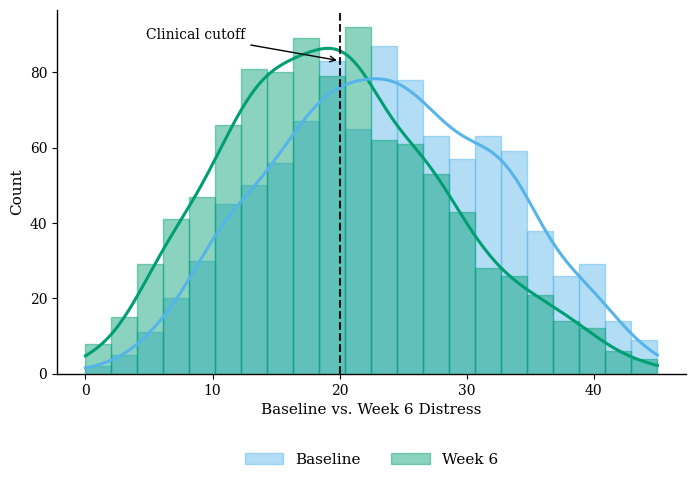

In [54]:
from functions.create_plots import plot_density_apa7_green_gold, export_figure_apa

fig, ax = plot_density_apa7_green_gold(
    df_all,
    show_baseline=True,
    y_col = "t1_distress_sum",
    baseline_col="t0_distress_sum",
    stat="counts",
    x_label="Baseline vs. Week 6 Distress",
    show_kde=True,
    legend_items="hist_only",    
)

In [55]:
export_figure_apa(fig, out_base="t1_distress_density_doublecol", dpi=300)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


Saved: t1_distress_density_doublecol.pdf/.eps/.svg/.tiff/.png/.jpg (dpi=300, jpg_quality=95)


In [56]:
fig, _ = plot_catboost_importance(
    feature_filename="cv_cat_shap_main_mean.csv",
    interaction_filename="cv_cat_shap_interactions_mean.csv",
    run_name="run_20260223_18",
    min_runs_present=2,
    top_pp_interactions=5,
    top_interactions=5,
    top_pre_therapist= 5,
    y_label_main="Mean |SHAP|",
    y_label_int="Mean |SHAP interaction|",
    title_main="SHAP (main effects)",
    title_int="SHAP (interactions)",
    gap_int_blocks = 0.4,
    show_legend=False)

NameError: name 'plot_catboost_importance' is not defined

In [ ]:
export_figure_apa(fig, out_base="cat_feature_importance", dpi=300)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


Saved: cat_feature_importance.pdf/.eps/.svg/.tiff/.png/.jpg (dpi=300, jpg_quality=95)


In [ ]:
from functions.create_plots_old import plot_density_apa7_green_gold, export_figure_apa
b

#### Calculate therapist effects

In [ ]:



# -----------------------------
# Run (expects df_all)
# -----------------------------
therapist_col = "therapist_id"
outcome_col = "t1_distress_sum"
baseline_col = "t0_distress_sum"

# Point estimates
pt_null = fit_icc_point(df_all, outcome_col=outcome_col, baseline_col=None,
                        therapist_col=therapist_col, reml=True, min_patients_per_therapist=2)

pt_adj  = fit_icc_point(df_all, outcome_col=outcome_col, baseline_col=baseline_col,
                        therapist_col=therapist_col, reml=True, min_patients_per_therapist=2)

# Bootstrap ICCs (cluster bootstrap by therapist)
boot_null = bootstrap_icc_cluster(
    df_all[[outcome_col, therapist_col]].dropna(),
    formula=f"{outcome_col} ~ 1",
    therapist_col=therapist_col,
    B=2000,          # thesis used 5000; 2000 is a practical start in Python
    reml=True,
    seed=123,
    min_patients_per_therapist=2
)

boot_adj = bootstrap_icc_cluster(
    df_all[[outcome_col, baseline_col, therapist_col]].dropna(),
    formula=f"{outcome_col} ~ {baseline_col}",
    therapist_col=therapist_col,
    B=2000,
    reml=True,
    seed=123,
    min_patients_per_therapist=2
)

# Save combined summaries
out_null = {
    "model": "null",
    "formula": pt_null["formula"],
    "icc_point": pt_null["icc"],
    "sigma2_therapist": pt_null["v_t"],
    "sigma2_resid": pt_null["v_e"],
    "n": pt_null["n"],
    "n_therapists": pt_null["n_therapists"],
    "icc_mean_boot": boot_null["boot_mean"],
    "icc_ci_low": boot_null["ci_low"],
    "icc_ci_high": boot_null["ci_high"],
    "n_boot_ok": boot_null["n_ok"],
    "B": boot_null["B"],
    "message": pt_null["message"],
    "boot_message": boot_null["message"],
}
pd.DataFrame([out_null]).to_csv("ICC_therapist_t1_distress_null_with_boot.csv", index=False)

out_adj = {
    "model": "baseline_adjusted",
    "formula": pt_adj["formula"],
    "icc_point": pt_adj["icc"],
    "sigma2_therapist": pt_adj["v_t"],
    "sigma2_resid": pt_adj["v_e"],
    "n": pt_adj["n"],
    "n_therapists": pt_adj["n_therapists"],
    "icc_mean_boot": boot_adj["boot_mean"],
    "icc_ci_low": boot_adj["ci_low"],
    "icc_ci_high": boot_adj["ci_high"],
    "n_boot_ok": boot_adj["n_ok"],
    "B": boot_adj["B"],
    "message": pt_adj["message"],
    "boot_message": boot_adj["message"],
}
pd.DataFrame([out_adj]).to_csv("ICC_therapist_t1_distress_adjusted_with_boot.csv", index=False)

print("[NULL] point ICC =", round(out_null["icc_point"], 6),
      "| boot mean =", round(out_null["icc_mean_boot"], 6),
      "| 95% CI [", round(out_null["icc_ci_low"], 6), ",", round(out_null["icc_ci_high"], 6), "]",
      "| n_boot_ok =", out_null["n_boot_ok"])

print("[ADJ ] point ICC =", round(out_adj["icc_point"], 6),
      "| boot mean =", round(out_adj["icc_mean_boot"], 6),
      "| 95% CI [", round(out_adj["icc_ci_low"], 6), ",", round(out_adj["icc_ci_high"], 6), "]",
      "| n_boot_ok =", out_adj["n_boot_ok"])


NameError: name 'np' is not defined